# Exploração da série CT skull

Este notebook confere a série antes da segmentação e da reconstrução 3D. Ele lê os arquivos DICOM, organiza os cortes pelas posições físicas informadas nos metadados, reúne-os em um volume e examina as intensidades.

## Dados e espaçamento

A série está em `data/skull/0051/0051/` e contém imagens DICOM de modalidade CT com resolução 512 x 512 pixels. O leitor usa `ImagePositionPatient` e `ImageOrientationPatient` para ordenar os cortes, e obtém o espaçamento entre cortes e o tamanho dos pixels dos metadados DICOM. Para esta série, o espaçamento em z é aproximadamente 1,5 mm e nos eixos x/y cerca de 0,48 mm.

Os valores de pixel são intensidades digitais de MRI, não unidades calibradas como HU. A escala de intensidade pode variar entre aquisições; os limiares usados nos notebooks seguintes são apenas experimentais, não clênicos.

## Bibliotecas utilizadas

- **pydicom**: lê os metadados e pixels dos arquivos DICOM.
- **NumPy**: organiza os pixels em matrizes e calcula estatésticas.
- **Matplotlib**: exibe cortes em escala de cinza e plota o histograma.
- **pathlib**: encontra os arquivos usando caminhos do projeto.

## 1. Localizar e contar os cortes

Os nomes dos arquivos não definem a ordem espacial. O carregador usa a posição e a orientação DICOM para ordenar os cortes e também verifica que eles pertencem ? mesma série.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sys

current_dir = Path.cwd().resolve()
project_candidates = [current_dir, *current_dir.parents]
project_candidates.extend(
    parent / "reconstrucao-cranio"
    for parent in [current_dir, *current_dir.parents]
)
project_root = next(
    (
        candidate
        for candidate in project_candidates
        if (candidate / "data" / "skull").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Não encontrei data/skull. "
        f"Diretório de trabalho atual do Jupyter: {current_dir}. "
        "Abra a pasta do projeto Reconstrução 3D de Imagens Médicas."
    )

src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)
from leitura import ler_dicom_volume

data_dir = project_root / "data" / "skull" / "0051" / "0051"
volume, spacing_zyx, image_files = ler_dicom_volume(data_dir)
print(f"Pasta do projeto: {project_root}")
print(f"Cortes DICOM encontrados: {len(image_files)}")
print(f"Primeiro corte espacial: {image_files[0].name}")
print(f"último corte espacial: {image_files[-1].name}")

Pasta do projeto: C:\Users\amart\Documents\pdi\Reconstrução 3D de Imagens Médicas\reconstrucao-cranio
Cortes DICOM encontrados: 108
Primeiro corte espacial: 1.3.12.2.1107.5.1.1.20706.20020604105245122.4.dcm
último corte espacial: 1.3.12.2.1107.5.1.1.20706.20020604110119564.4.dcm


## 2. Ler e exibir um corte

`ler_dicom_volume` lê os arquivos DICOM e retorna as imagens organizadas em um volume NumPy, o espaçamento físico e os caminhos na mesma ordem espacial. `shape` mostra as dimensões, `dtype` informa como os valores dos pixels são armazenados e `min`/`max` mostram os extremos de intensidade.

Arquivo: 1.3.12.2.1107.5.1.1.20706.20020604105704710.4.dcm
Dimensões: (512, 512)
Tipo de dado: uint16
Intensidade mínima: 0
Intensidade máxima: 2692


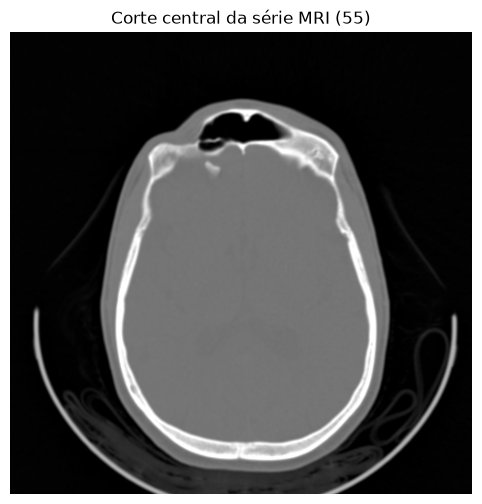

In [2]:
sample_index = len(image_files) // 2
sample = volume[sample_index]
print(f"Arquivo: {image_files[sample_index].name}")
print(f"Dimensões: {sample.shape}")
print(f"Tipo de dado: {sample.dtype}")
print(f"Intensidade mínima: {sample.min()}")
print(f"Intensidade máxima: {sample.max()}")

plt.figure(figsize=(6, 6))
plt.imshow(sample, cmap="gray", vmin=0, vmax=np.percentile(sample, 99))
plt.title(f"Corte central da série MRI ({sample_index + 1})")
plt.axis("off");

## 3. Organizar os cortes e conferir o volume

`np.stack` empilha as matrizes na ordem dos arquivos, formando uma matriz 3D: profundidade, linhas e colunas `(z, y, x)`. Aqui, cada voxel continua sendo apenas um valor de intensidade; esta organização ainda não é segmentação.

In [3]:
print(f"Dimensões do volume (z, y, x): {volume.shape}")
print(f"Tipo de dado: {volume.dtype}")
print(f"Espaçamento DICOM (z, y, x), em mm: {spacing_zyx}")

if volume.ndim != 3 or volume.shape[0] != len(image_files):
    raise ValueError("O volume DICOM não corresponde à quantidade de cortes lidos.")

Dimensões do volume (z, y, x): (108, 512, 512)
Tipo de dado: uint16
Espaçamento DICOM (z, y, x), em mm: (1.5, 0.4785156, 0.4785156)


## 4. Examinar as intensidades

O mínimo e o máximo mostram os extremos do volume. Os percentis 1 e 99 ajudam a resumir a faixa que contém a maior parte dos valores sem depender apenas de pixels muito raros. O histograma agrupa as intensidades em intervalos: a altura de cada barra indica quantos voxels caem naquele intervalo. Essas medidas são exploratórias e não definem um limiar de segmentação.

Intensidade mínima do volume: 0
Intensidade máxima do volume: 4057
Percentil 1: 0.0
Percentil 99: 2234.0


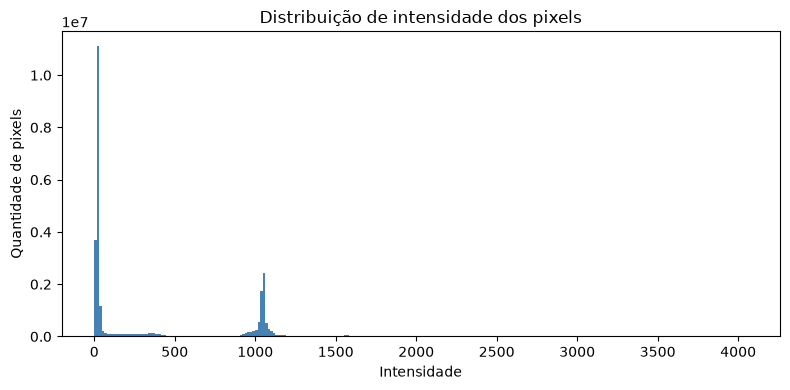

In [4]:
percentil_1, percentil_99 = np.percentile(volume, [1, 99])
print(f"Intensidade mínima do volume: {volume.min()}")
print(f"Intensidade máxima do volume: {volume.max()}")
print(f"Percentil 1: {percentil_1:.1f}")
print(f"Percentil 99: {percentil_99:.1f}")

plt.figure(figsize=(8, 4))
plt.hist(volume.ravel(), bins=256, color="steelblue")
plt.title("Distribuição de intensidade dos pixels")
plt.xlabel("Intensidade")
plt.ylabel("Quantidade de pixels")
plt.tight_layout();

## 5. Comparar diferentes cortes

A figura compara o primeiro, o central e o último corte. O índice começa em zero no Python: o índice `0` representa o primeiro arquivo, e `len(volume) // 2` seleciona um corte central.

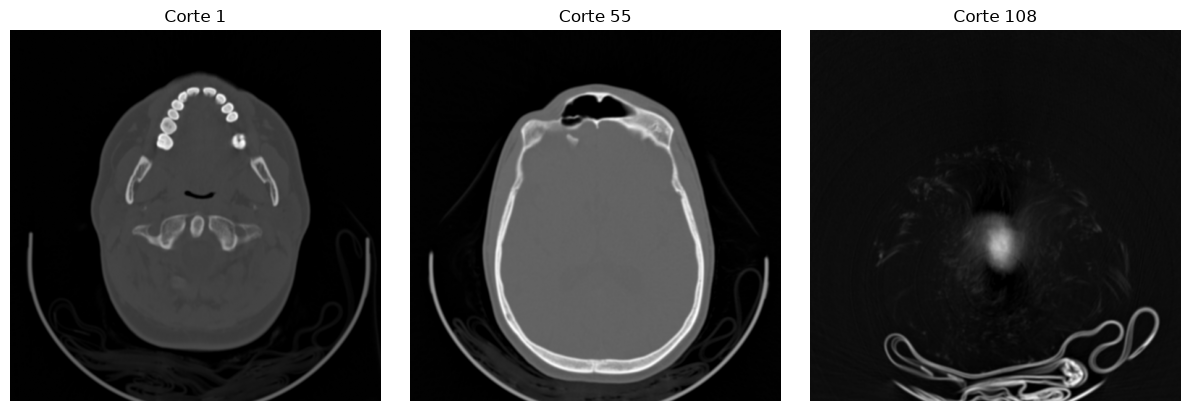

In [5]:
indices = [0, len(volume) // 2, len(volume) - 1]
fig, axes = plt.subplots(1, len(indices), figsize=(12, 4), layout="constrained")

for ax, index in zip(axes, indices):
    ax.imshow(volume[index], cmap="gray")
    ax.set_title(f"Corte {index + 1}")
    ax.axis("off")

plt.show()

## Próxima etapa

Confirme a contagem, as dimensões, o tipo e a exibição dos cortes. Este notebook termina na leitura e exploração; não realiza filtragem, limiarização, operações morfolêgicas nem reconstrução 3D.